# Analisi iniziale dei dati

## Evoluzione delle anime negli anni

In [8]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from matplotlib.pyplot import legend

from solution.utils import *
from solution.utils.details_utils import parse_genres_column, explode_genres


In [9]:
# load dataset
details = pd.read_csv("../dataset/cleaned/details_cleaned.csv")
favs = pd.read_csv("../dataset/cleaned/favs_cleaned.csv")
recommendations = pd.read_csv("../dataset/cleaned/recommendations_cleaned.csv")
stats = pd.read_csv("../dataset/cleaned/stats_cleaned.csv")
#ratings = pd.read_csv("../dataset/cleaned/ratings_cleaned.csv")


In [10]:
details['start_date'] = pd.to_datetime(details['start_date'], errors='coerce')
details['year'] = details['start_date'].dt.year.astype("Int64")


### Nella prima parte viene presentata un’analisi temporale della produzione, utile a contestualizzare storicamente il fenomeno. Le sezioni successive approfondiscono aspetti legati alla popolarità, ai rating degli utenti e alle fonti di ispirazione

In [11]:
details = details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Dagli anni ’70 in poi si osserva una **crescita** quasi **esponenziale** del numero di anime prodotti, con un’accelerazione marcata dopo il 2000.
Negli ultimi anni, invece, il trend mostra oscillazioni e un leggero **calo**, suggerendo una possibile fase di saturazione del mercato.

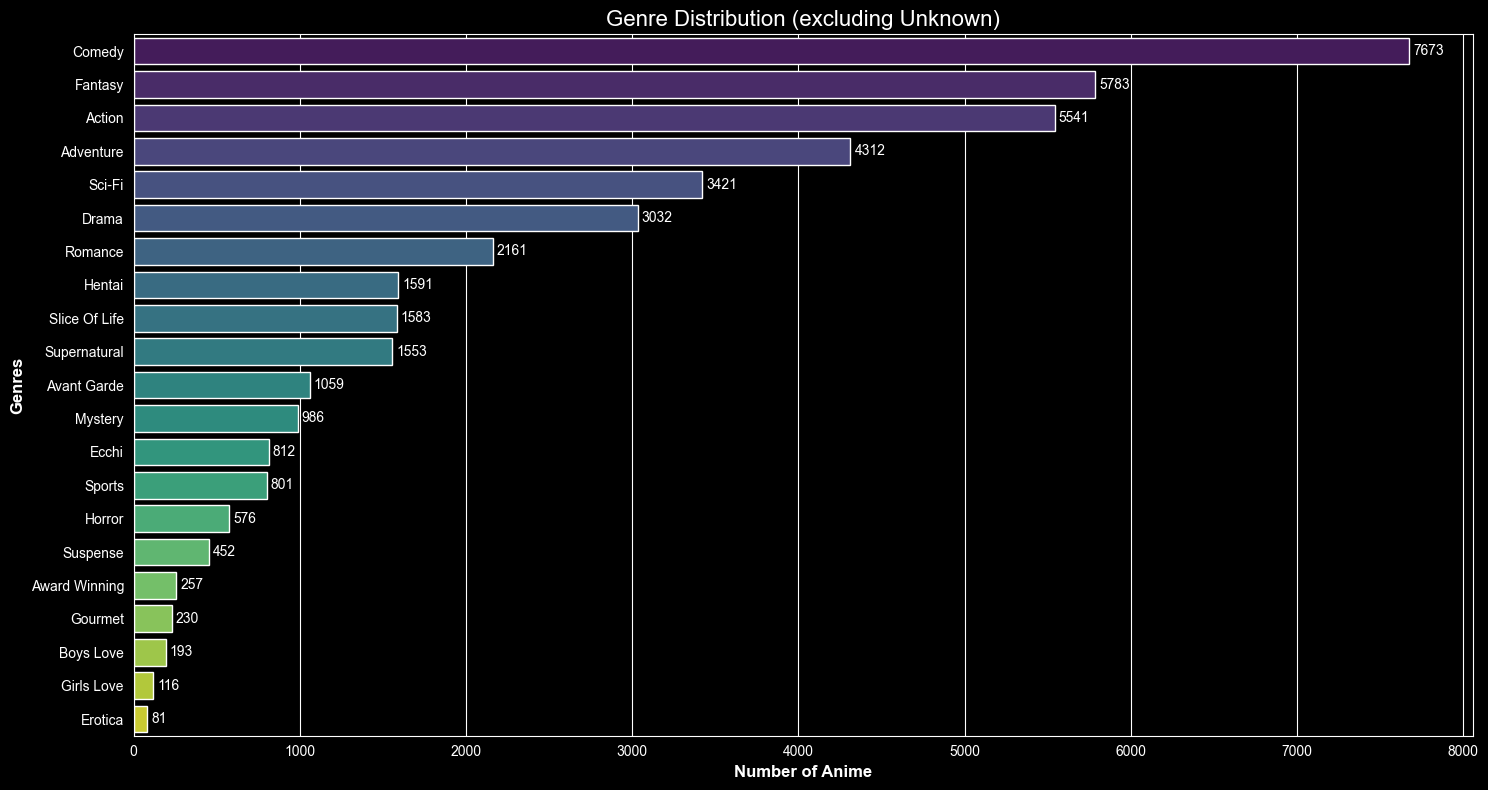

In [12]:
# Convert genres from string to list
details['genres'] = details['genres'].apply(ast.literal_eval)
# Explode genres for plotting
details = details.explode('genres').dropna(subset=['genres'])
# Count genres
genre_count = details['genres'].value_counts().reset_index()
genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## Evoluzione dei principali generi anime nel tempo

### Come cambiano i generi anime dal 1917 a oggi

In [13]:
details = details.dropna(subset=['start_date'])
print(details)
# filtro anni VALIDI
details = details[(details['year'] >= 1917) & (details['year'] <= 2024)]
# explode generi
genres_df = details.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible='legendonly'
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()